# Tutorial 61: nx-Graph

This example demonstrates how to use the SIR_3S_to_nx_graph() of the SIR 3S Toolkit to generate a nx-Graph based on a SIR 3S model.

# SIR 3S Installation

In [1]:
SIR3S_SIRGRAF_DIR = r"C:\3S\SIR 3S\SirGraf-90-15-00-24_Quebec-Upd2" #change to local path

# Imports

Note: The SIR 3S Toolkit requires the Sir3S_Toolkit.dll included in SIR 3S installations (version Quebec and higher).

In [2]:
import sir3stoolkit

The core of sir3stoolkit is a Python wrapper around basic functionality of SIR 3S, offering a low-level access to the creation, modification and simulation of SIR 3S models. In the future pure python subpackages may be added.

In [3]:
from sir3stoolkit.core import wrapper

In [4]:
from sir3stoolkit.mantle.alternative_models import SIR3S_Model_Alternative_Models

In [5]:
sir3stoolkit

<module 'sir3stoolkit' from 'C:\\Users\\aUsername\\3S\\sir3stoolkit\\src\\sir3stoolkit\\__init__.py'>

The wrapper package has to be initialized with reference to a SIR 3S (SirGraf) installation.

In [6]:
wrapper.Initialize_Toolkit(SIR3S_SIRGRAF_DIR)

[2026-11-25 16:26:45,449] INFO in sir3stoolkit.core.wrapper: [Initialization] Using provided SirGraf path: C:\3S\SIR 3S\SirGraf-90-15-00-24_Quebec-Upd2


[2026-11-25 16:26:45,449] INFO in sir3stoolkit.core.wrapper: [Initialization] Using provided SirGraf path: C:\3S\SIR 3S\SirGraf-90-15-00-24_Quebec-Upd2


[2026-11-25 16:26:45,477] INFO in sir3stoolkit.core.wrapper: [Initialization] Initializing toolkit with SirGraf path: C:\3S\SIR 3S\SirGraf-90-15-00-24_Quebec-Upd2


[2026-11-25 16:26:45,646] INFO in sir3stoolkit.core.wrapper: [Initialization] Sir3S_Toolkit.dll file version 90.15.11.0 (matches this sir3stoolkit version).


### Additional imports

In [7]:
import networkx as nx
import matplotlib.pyplot as plt
import logging

# Initialization

In [8]:
s3s = SIR3S_Model_Alternative_Models()

[2026-11-25 16:26:46,451] INFO in sir3stoolkit.core.wrapper: [Model Class Initialization] Initialization complete


# Open Model

The tutorial uses *Network 3*, a fictional district heating network shared by the mantle tutorials: a heat plant (in its own container "Heizwerk"), about 180 consumers, a ring road and two longitudinal sections, calculated over one day. It is built from scratch with the SIR 3S Toolkit by [Network3.py](https://github.com/3SConsult/sir3stoolkit/blob/main/docs/source/networks/Network3.py); `Network3.db3` is included in the tutorial's ZIP archive.

Its elements have unique ID references (IDREFERENZ), e.g. `VL-HS-01` for the first supply pipe of the main street. They are used below to look up tks with [GetTkFromIDReference()](https://3sconsult.github.io/sir3stoolkit/references/sir3stoolkit.core.html#sir3stoolkit.core.wrapper.SIR3S_Model.GetTkFromIDReference) - the tks themselves differ between builds of the model.

In [9]:
dbFilePath=r"Network3.db3"

In [10]:
s3s.OpenModel(dbName=dbFilePath,
              providerType=s3s.ProviderTypes.SQLite,
              Mid="M-1-0-1",
              saveCurrentlyOpenModel=False,
              namedInstance="",
              userID="",
              password="")

[2026-11-25 16:26:52,337] INFO in sir3stoolkit.core.wrapper: Model is open for further operation


# Calculate Model

In [11]:
s3s.ExecCalculation(True) # To ensure result data

[2026-11-25 16:26:57,371] INFO in sir3stoolkit.core.wrapper: Model Calculation is complete


# Generate nx Graph

We can use the [SIR_3S_to_nx_graph()](https://3sconsult.github.io/sir3stoolkit/references/sir3stoolkit.mantle.html#sir3stoolkit.mantle.alternative_models.SIR3S_Model_Alternative_Models.SIR_3S_to_nx_graph) method to create a nx graph representing a SIR 3S model.

In [12]:
logging.disable(logging.INFO)

In [13]:
G=s3s.SIR_3S_to_nx_graph()

[2026-11-25 16:26:57,479] WARNING in sir3stoolkit.mantle.dataframes: [model_data] Spatial Reference Identifier (SRID) not defined in model. DataFrame cannot be transformed to GeoDataFrame but geometry column can be created independently of SRID. Returning regular DataFrame with a geometry column.


[2026-11-25 16:26:57,640] WARNING in sir3stoolkit.mantle.dataframes: [model_data] Spatial Reference Identifier (SRID) not defined in model. DataFrame cannot be transformed to GeoDataFrame but geometry column can be created independently of SRID. Returning regular DataFrame with a geometry column.


[2026-11-25 16:26:57,726] WARNING in sir3stoolkit.mantle.dataframes: [model_data] Spatial Reference Identifier (SRID) not defined in model. DataFrame cannot be transformed to GeoDataFrame but geometry column can be created independently of SRID. Returning regular DataFrame with a geometry column.


[2026-11-25 16:26:57,793] WARNING in sir3stoolkit.mantle.dataframes: [model_data] Spatial Reference Identifier (SRID) not defined in model. DataFrame cannot be transformed to GeoDataFrame but geometry column can be created independently of SRID. Returning regular DataFrame with a geometry column.


[2026-11-25 16:26:57,847] WARNING in sir3stoolkit.mantle.dataframes: [model_data] Spatial Reference Identifier (SRID) not defined in model. DataFrame cannot be transformed to GeoDataFrame but geometry column can be created independently of SRID. Returning regular DataFrame with a geometry column.


[2026-11-25 16:26:57,943] WARNING in sir3stoolkit.mantle.dataframes: [model_data] Spatial Reference Identifier (SRID) not defined in model. DataFrame cannot be transformed to GeoDataFrame but geometry column can be created independently of SRID. Returning regular DataFrame with a geometry column.


[2026-11-25 16:26:58,008] WARNING in sir3stoolkit.mantle.dataframes: [model_data] Spatial Reference Identifier (SRID) not defined in model. DataFrame cannot be transformed to GeoDataFrame but geometry column can be created independently of SRID. Returning regular DataFrame with a geometry column.


In [14]:
logging.disable(logging.NOTSET)

# View generated Graph

As you can see below the graph does not contain any additional properties or result values. 

Note the current limitations of the graph:
- Node ids and the tk attributes in the graph are int64 (e.g. `node_attrs[node_a]` below), while everywhere else in sir3stoolkit tks are strings - convert with `int(tk)` / `str(tk)` when matching with DataFrames.
- The graph is an `nx.DiGraph`, which holds only one edge per node pair: elements in parallel between the same two nodes (e.g. several consumers on one supply/return pair, parallel pipes) overwrite each other, so edges can be missing ([#25](https://github.com/3SConsult/sir3stoolkit/issues/25)). In Network 3 the two parallel network pumps of the heat plant are affected: one of 775 edge elements is missing. Compare `G.number_of_edges()` with the number of edge elements to check your model.
- The graph needs a calculated model ([#26](https://github.com/3SConsult/sir3stoolkit/issues/26)), hence the calculation above.

## Node and Edge Attributes

In [15]:
node_attrs = {n: data for n, data in G.nodes(data=True)}

In [16]:
# the first two supply nodes of the main street, as int like the node ids of the graph
node_a = int(s3s.GetTkFromIDReference("V-HS-00", s3s.ObjectTypes.Node))
node_b = int(s3s.GetTkFromIDReference("V-HS-01", s3s.ObjectTypes.Node))
node_attrs[node_a]

{'tk': 5431799190353317880,
 'Fkcont': 5586885184287337261,
 'geometry': <POINT Z (100 1000 198.09)>}

In [17]:
edge_attrs = {(u, v): data for u, v, data in G.edges(data=True)}

In [18]:
edge_attrs[(node_a, node_b)]['Fkcont']

5586885184287337261

## Connected ?

In [19]:
nx.is_weakly_connected(G) # Is connected as an undirected graph

True

## Plot

In [20]:
def plot_nx_graph(G, main_container):
    # Extract node positions from geometry and filter by Fkcont
    pos = {
        node_id: (data['geometry'].x, data['geometry'].y)
        for node_id, data in G.nodes(data=True)
        if 'geometry' in data and hasattr(data['geometry'], 'x') and hasattr(data['geometry'], 'y')
        and data.get('Fkcont') == main_container
    }

    # Extract edges with valid geometry and both nodes in pos
    edges = [
        (u, v, data) for u, v, data in G.edges(data=True)
        if u in pos and v in pos and 'geometry' in data and data['geometry'].geom_type != 'Point'
    ]

    # Plot
    plt.figure(figsize=(20, 14))
    for _, _, data in edges:
        geom = data['geometry']
        x, y = geom.xy
        plt.plot(x, y, color='black', linewidth=1)

    # Only draw nodes that have positions
    nx.draw_networkx_nodes(G, pos=pos, nodelist=list(pos.keys()), node_color='black', node_size=10)
    plt.title(f"nx-Graph'{main_container}'")
    plt.axis('equal')
    plt.show()

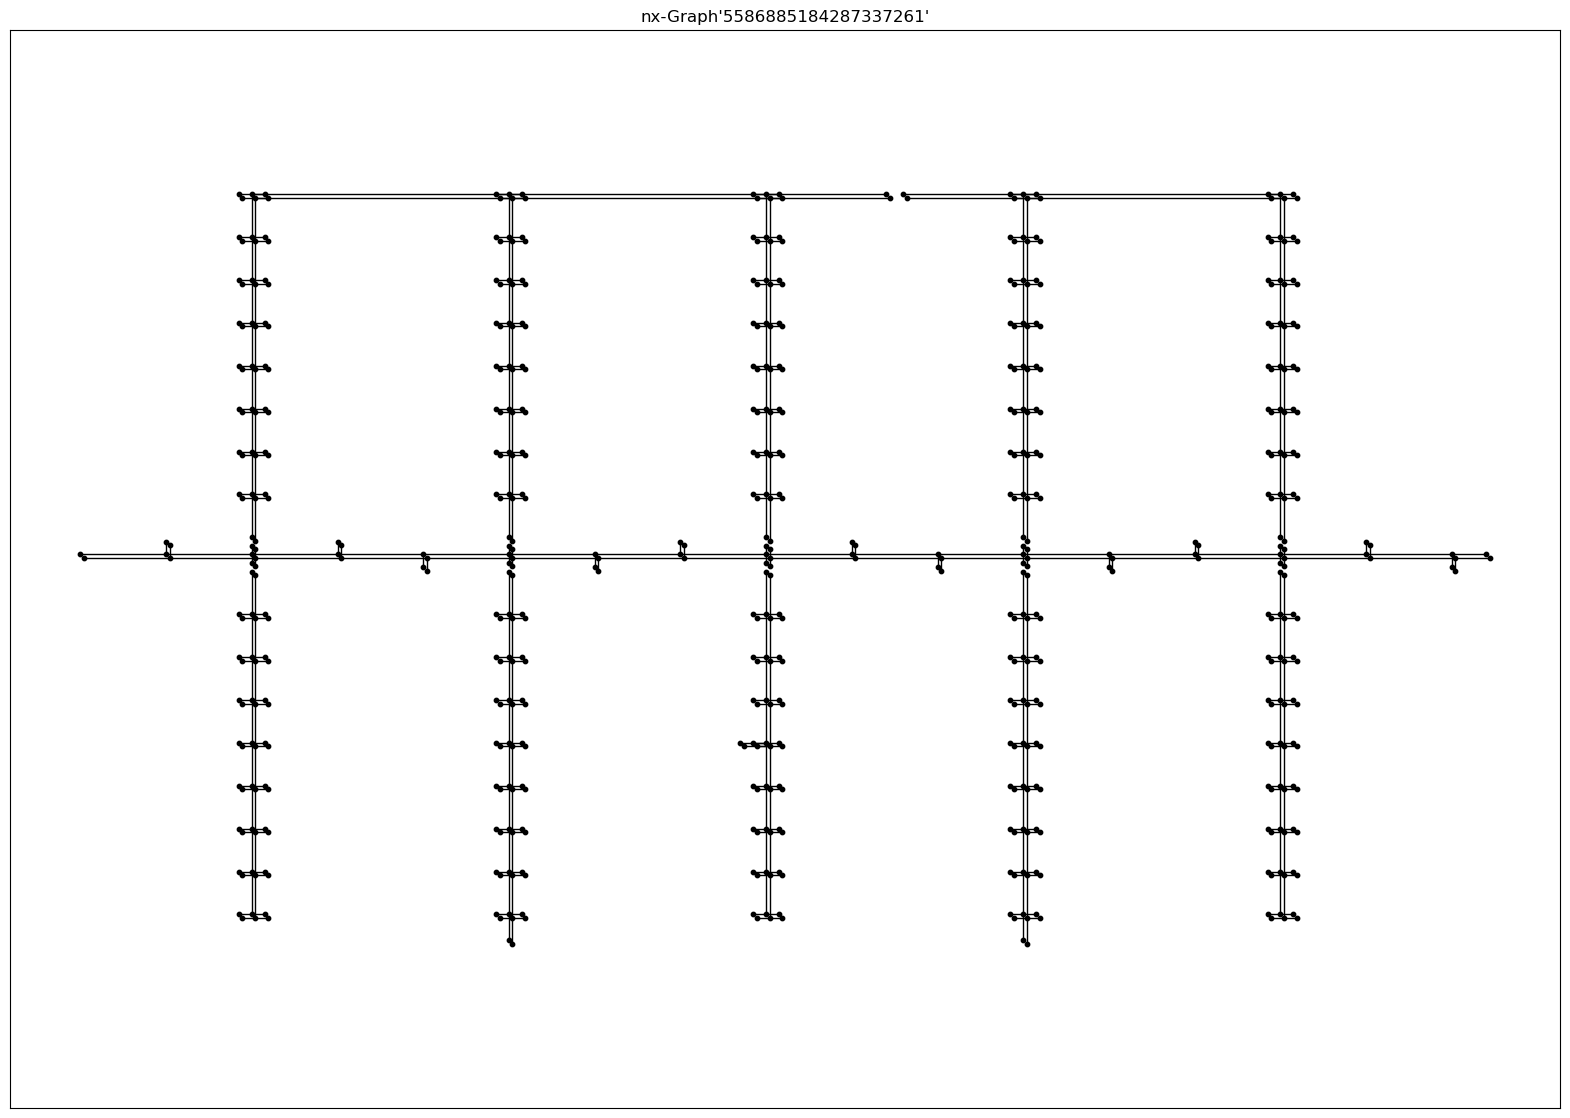

In [21]:
plot_nx_graph(G, int(s3s.GetMainContainer()[0]))

# Add properities to graph

Now, we can model data properties and result properties to the nodes and edges.

In [22]:
props_to_add = ["Kvr", "T", "BCIND"]  
G = s3s.add_properties_to_graph(
    G=G,
    element_type="Node",
    properties=props_to_add,
)

[2026-11-25 16:26:58,792] INFO in sir3stoolkit.mantle.alternative_models: [graph] Enriching graph with properties for element_type='Node'


[2026-11-25 16:26:58,792] INFO in sir3stoolkit.mantle.alternative_models: [graph] Using 1 model_data props and 2 result props.


[2026-11-25 16:26:58,794] INFO in sir3stoolkit.mantle.dataframes: [model_data] Generating model_data dataframe for element type: ObjectTypes.Node


[2026-11-25 16:26:58,795] INFO in sir3stoolkit.mantle.dataframes: [model_data] Retrieved 592 element(s) of element type ObjectTypes.Node.


[2026-11-25 16:26:58,798] INFO in sir3stoolkit.mantle.dataframes: [Resolving model_data Properties] Using 1 model_data properties.


[2026-11-25 16:26:58,798] INFO in sir3stoolkit.mantle.dataframes: [model_data] Retrieving model_data properties ['Kvr']...


... (14 outputs left out)

[2026-11-25 16:26:59,127] INFO in sir3stoolkit.mantle.dataframes: [results] DataFrame assembled (0.0 s).


[2026-11-25 16:26:59,127] INFO in sir3stoolkit.mantle.dataframes: [results] Done. Shape: (1, 1184) (0.3 s in total)


[2026-11-25 16:26:59,136] INFO in sir3stoolkit.mantle.alternative_models: Index(['tk', 'Kvr', 'T', 'BCIND'], dtype='object')


[2026-11-25 16:26:59,144] INFO in sir3stoolkit.mantle.alternative_models: [graph] Enrichment summary for element_type='Node': nodes_updated=592; edges_updated=0; cols_added=['Kvr', 'T', 'BCIND']


In [23]:
node_attrs = {n: data for n, data in G.nodes(data=True)}

In [24]:
node_attrs[node_a]

{'tk': 5431799190353317880,
 'Fkcont': 5586885184287337261,
 'geometry': <POINT Z (100 1000 198.09)>,
 'Kvr': 1,
 'T': 85.0,
 'BCIND': 17.0}

In [25]:
props_to_add = ["DN", "L", "JV", "PHR"]  
G = s3s.add_properties_to_graph(
    G=G,
    element_type="Pipe",
    properties=props_to_add,
)

[2026-11-25 16:26:59,172] INFO in sir3stoolkit.mantle.alternative_models: [graph] Enriching graph with properties for element_type='Pipe'


[2026-11-25 16:26:59,172] INFO in sir3stoolkit.mantle.alternative_models: [graph] Using 2 model_data props and 2 result props.


[2026-11-25 16:26:59,172] INFO in sir3stoolkit.mantle.dataframes: [model_data] Generating model_data dataframe for element type: ObjectTypes.Pipe


[2026-11-25 16:26:59,172] INFO in sir3stoolkit.mantle.dataframes: [model_data] Retrieved 572 element(s) of element type ObjectTypes.Pipe.


[2026-11-25 16:26:59,178] INFO in sir3stoolkit.mantle.dataframes: [Resolving model_data Properties] Using 2 model_data properties.


[2026-11-25 16:26:59,178] INFO in sir3stoolkit.mantle.dataframes: [model_data] Retrieving model_data properties ['DN', 'L']...


... (14 outputs left out)

[2026-11-25 16:26:59,502] INFO in sir3stoolkit.mantle.dataframes: [results] DataFrame assembled (0.0 s).


[2026-11-25 16:26:59,515] INFO in sir3stoolkit.mantle.dataframes: [results] Done. Shape: (1, 1144) (0.2 s in total)


[2026-11-25 16:26:59,519] INFO in sir3stoolkit.mantle.alternative_models: Index(['tk', 'DN', 'L', 'JV', 'PHR'], dtype='object')


[2026-11-25 16:26:59,524] INFO in sir3stoolkit.mantle.alternative_models: [graph] Enrichment summary for element_type='Pipe': nodes_updated=0; edges_updated=572; cols_added=['DN', 'L', 'JV', 'PHR']


In [26]:
edge_attrs = {(u, v): data for u, v, data in G.edges(data=True)}

In [27]:
edge_attrs[(node_a, node_b)]

{'Fkcont': 5586885184287337261,
 'L': 100,
 'element type': 'Pipe',
 'fkKI': 5431799190353317880,
 'fkKK': 5141021320509852354,
 'geometry': <LINESTRING Z (100 1000 198.09, 200 1000 197.95)>,
 'tk': 5448887806005001177,
 'DN': 250,
 'JV': 0.08453957736492157,
 'PHR': 0.008453958667814732}